# CIKM2017 数据质量审计

## tl;dr

训练集 10,000 条，Test A/B 各 2,000 条；ID 唯一、标签有限、抽样雷达行均可解析。训练标签明显长尾，且三份数据均出现极少量 `-1` 雷达哨兵值，因此加载器会在内存中将负值置零。

## Context & Methods

审计粒度为单个 CIKM2017 样本。ID和标签检查覆盖全部14,000条记录；雷达载荷检查在每个文件中等距抽样128条。原始文件保持只读。

### Key Assumptions

- 测试集标签 `-1` 表示未知目标，不用于精度评估。
- 雷达值 `-1` 视为缺测哨兵，而不是有效反射率。
- 数据没有日期、地点或天气过程字段，因此无法验证事件级泄漏。

## Data

读取项目随附的 `data_audit.json`，该文件由 `data_audit.py` 生成。

In [1]:
import json
from pathlib import Path

audit_path = Path('../examples/data-audit-current/data_audit.json')
audit = json.loads(audit_path.read_text(encoding='utf-8'))
print('Loaded:', audit_path)

Loaded: ../examples/data-audit-current/data_audit.json


## Results

In [2]:
for name in ('train', 'test_a', 'test_b'):
    item = audit[name]
    radar = item['radar_sample']
    print(
        f"{name:6s} rows={item['rows']:5d} unique_ids={item['unique_ids']:5d} "
        f"negative_radar={radar['mean_negative_rate'] * 1e6:.3f} ppm "
        f"zero_radar={radar['mean_zero_rate']:.2%}"
    )

q = audit['train']['label_quantiles']
print(f"train label q50={q['q50']:.1f}, q90={q['q90']:.1f}, q95={q['q95']:.1f}, max={q['q100']:.1f}")

train  rows=10000 unique_ids=10000 negative_radar=1.532 ppm zero_radar=40.88%
test_a rows= 2000 unique_ids= 2000 negative_radar=0.549 ppm zero_radar=41.08%
test_b rows= 2000 unique_ids= 2000 negative_radar=0.677 ppm zero_radar=40.50%
train label q50=8.0, q90=37.0, q95=45.3, max=138.4


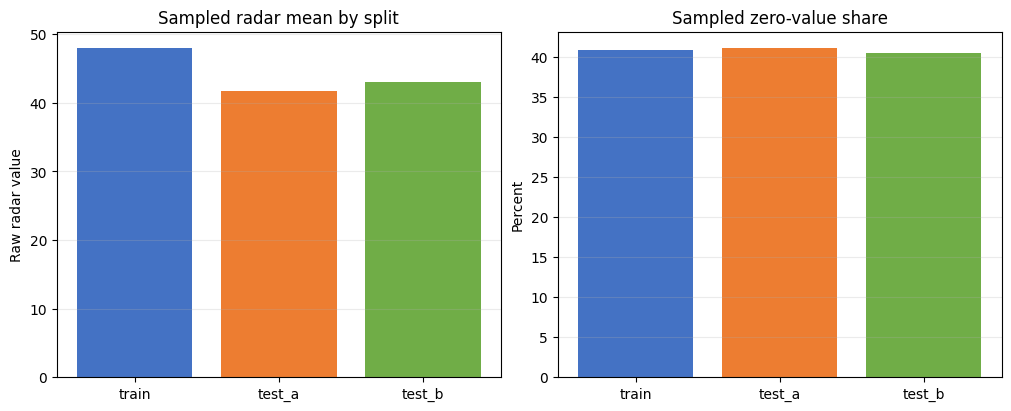

In [3]:
import matplotlib.pyplot as plt

names = ['train', 'test_a', 'test_b']
mean_radar = [audit[name]['radar_sample']['mean_of_sample_means'] for name in names]
zero_rate = [audit[name]['radar_sample']['mean_zero_rate'] * 100 for name in names]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].bar(names, mean_radar, color=['#4472C4', '#ED7D31', '#70AD47'])
axes[0].set_title('Sampled radar mean by split')
axes[0].set_ylabel('Raw radar value')
axes[0].grid(axis='y', alpha=.25)
axes[1].bar(names, zero_rate, color=['#4472C4', '#ED7D31', '#70AD47'])
axes[1].set_title('Sampled zero-value share')
axes[1].set_ylabel('Percent')
axes[1].grid(axis='y', alpha=.25)
fig.savefig('../examples/data-audit-current/audit_overview.png', dpi=180)
plt.show()

## Takeaways

1. 数据行数和提交模板一致，没有发现重复ID或非有限标签。
2. 训练标签从0到138.4，中位数8.0、q95为45.3，必须保留强降水专项损失和指标。
3. 抽样雷达负值率约为百万分之一，影响很小但应稳定处理；加载器已执行只读内存清洗。
4. 缺少事件元数据是最主要的数据限制；正式结论应使用分层划分、多随机种子和消融实验。